

*   **光变曲线星表 (Lightcurves catalog)**：每个 ZTF 天体对应一行，包含一个嵌套列，用于存储完整的光度时间序列——时间戳、星等、不确定度和质量标志。
*   **天体表 (Objects Table)**：每个 ZTF 天体对应一行，包含折叠后的光变曲线指标，例如星等均方根 (RMS)、卡方变异性统计量、有效观测次数以及平均星等。

[`lsdb`](https://docs.lsdb.io/en/latest/index.html) Python 库提供了一个便捷的接口来处理 HATS 星表，包括空间查询和基于天体 ID 的查找。

访问 ZTF 光变曲线的两个常见入口：

1.  **天体 ID (Object IDs)**：拥有特定的 ZTF 天体 ID——（这些 ID 可能）来自之前的查询、星表交叉匹配或已发布的天体列表——并希望直接获取它们的光变曲线。
2.  **赤经/赤纬 (RA/Dec)**：拥有天球坐标，并希望获取给定半径内所有的 ZTF 天体。

### Imports

In [1]:
import s3fs
import lsdb
import pyarrow.parquet as pq
from astropy.coordinates import SkyCoord
import pandas as pd
from astropy import units as u
import os
import matplotlib.pyplot as plt
from dask.distributed import Client

In [2]:
pd.set_option("display.max_colwidth", None)
pd.set_option("display.min_rows", 18)

### 1. Locate ZTF DR24 HATS Catalogs in the Cloud

In [3]:
ztf_bucket = "ipac-irsa-ztf" #存储桶
ztf_lc_hats_prefix = "ztf/enhanced/dr24/lc/hats" # Lightcurves catalog
ztf_objects_hats_prefix = "ztf/enhanced/dr24/objects/hats" # Objects Table

[`s3f3`](https://s3fs.readthedocs.io/en/latest/) 给出了一个python接口可以把云端的AWS S3 buckets类似地挂载到本地的文件系统中来访问

In [4]:
s3 = s3fs.S3FileSystem(anon=True)

In [5]:
s3.ls(f"{ztf_bucket}/{ztf_lc_hats_prefix}")  #ZTF DR24 Lightcurves HATS Collection

['ipac-irsa-ztf/ztf/enhanced/dr24/lc/hats/README.txt',
 'ipac-irsa-ztf/ztf/enhanced/dr24/lc/hats/collection.properties',
 'ipac-irsa-ztf/ztf/enhanced/dr24/lc/hats/download-aws-cli.sh',
 'ipac-irsa-ztf/ztf/enhanced/dr24/lc/hats/download-irsa-wget.sh',
 'ipac-irsa-ztf/ztf/enhanced/dr24/lc/hats/ztf_dr24_lc-hats',
 'ipac-irsa-ztf/ztf/enhanced/dr24/lc/hats/ztf_dr24_lc-hats_index_objectid',
 'ipac-irsa-ztf/ztf/enhanced/dr24/lc/hats/ztf_dr24_lc-hats_margin_10arcsec']

In [6]:
ztf_lc_schema_path = "ztf_dr24_lc-hats/dataset/_common_metadata"  # ztf_dr24_lc-hats is the catalog name identified above

In [7]:
s3.ls(f"{ztf_bucket}/{ztf_objects_hats_prefix}")

['ipac-irsa-ztf/ztf/enhanced/dr24/objects/hats/README.txt',
 'ipac-irsa-ztf/ztf/enhanced/dr24/objects/hats/collection.properties',
 'ipac-irsa-ztf/ztf/enhanced/dr24/objects/hats/download-aws-cli.sh',
 'ipac-irsa-ztf/ztf/enhanced/dr24/objects/hats/download-irsa-wget.sh',
 'ipac-irsa-ztf/ztf/enhanced/dr24/objects/hats/ztf_dr24_objects-hats',
 'ipac-irsa-ztf/ztf/enhanced/dr24/objects/hats/ztf_dr24_objects-hats_index_oid',
 'ipac-irsa-ztf/ztf/enhanced/dr24/objects/hats/ztf_dr24_objects-hats_margin_10arcsec']

In [8]:
ztf_objects_schema_path = "ztf_dr24_objects-hats/dataset/_common_metadata"  # ztf_dr24_objects-hats is the catalog name identified above

### 2.Explore the Catalog Schema

In [9]:
def pq_schema_to_df(schema):
    """Convert a PyArrow schema to a Pandas DataFrame."""
    return pd.DataFrame(
        [
            (
                field.name,
                str(field.type),
                field.metadata.get(b"unit", b"").decode(),
                field.metadata.get(b"description", b"").decode()
            )
            for field in schema
        ],
        columns=["name", "type", "unit", "description"]
    )

In [10]:
ztf_lc_schema = pq.read_schema(
    f"s3://{ztf_bucket}/{ztf_lc_hats_prefix}/{ztf_lc_schema_path}",
    filesystem=s3
)
ztf_lc_schema_df = pq_schema_to_df(ztf_lc_schema)
ztf_lc_schema_df

,name,type,unit,description
0,_healpix_29,int64,,HEALPix order 29 pixel index.
1,_healpix_19,int64,,HEALPix order 19 pixel index.
2,_healpix_9,int32,,HEALPix order 9 pixel index.
3,objectid,int64,,"Unique Object Identifier. This is the ""oid"" that is returned by queries on the Objects Table. This ID can be used to retrieve additional metadata for an Object or lightcurve."
4,filterid,int8,,Filter for the lightcurve photometry: 1 => g; 2 => r; 3 => i.
5,fieldid,int16,,"The survey Field Identifier. Lightcurves in DR24 are spread across 1,286 fields. This identifier can be used to retrieve additional archive metadata."
6,rcid,int8,,"The readout-channel Identifier (or CCD-Quadrant index) that contains the object. The rcid runs from 0 to 63 over the ZTF focal plane (https://irsa.ipac.caltech.edu/data/ZTF/docs/common/ztf_focal_plane.jpg). In combination with fieldid, this can be used to retrieve additional archive metadata."
7,objra,float,deg,"Object Right Ascension from the input Reference Image (seed) catalog (https://irsa.ipac.caltech.edu/data/ZTF/docs/releases/dr24/ztf_release_notes_dr24.pdf) corresponding to the fieldID, rcid, and filterid [decimal degrees]."
8,objdec,float,deg,"Object Declination from the input Reference Image (seed) catalog (https://irsa.ipac.caltech.edu/data/ZTF/docs/releases/dr24/ztf_release_notes_dr24.pdf) corresponding to the fieldid, rcid, and filterid [decimal degrees]."
9,nepochs,int64,,"The number of observation epochs in the lightcurve for this object, included in this data release only."


In [11]:
ztf_lc_columns = ["objectid", "objra", "objdec", "filterid", "nepochs", "lightcurve"]

### 3. Get Light Curves by Object ID

有ZTF 物体的ids也可以直接通过索引获取

#### 3.1 Open the Lightcurves Catalog

[`lazily`](https://docs.lsdb.io/en/latest/tutorials/lazy_operations.html)可以加载数据框架而不实际读取数据

In [ ]:
s3 = s3fs.S3FileSystem(anon=True)   # 公共桶，匿名访问

print(s3.cat(f"{ztf_bucket}/{ztf_objects_hats_prefix}/README.txt").decode("utf-8"))


ZTF DR24 Objects Table - HATS Collection

Version Date: 2026-05-08

This is an enhanced version of Zwicky Transient Facility's ZTF DR24 Objects Table
(https://irsa.ipac.caltech.edu/data/ZTF/docs/releases/ztf_release_notes_latest), created by IRSA
(http://irsa.ipac.caltech.edu). It is structured as a HATS (Hierarchical Adaptive Tiling Scheme)
Collection and includes three Apache Parquet datasets: HATS Catalog, Margin Cache, and Index Table.
HATS Catalogs are partitioned spatially using an adaptive-order HEALPix (Hierarchical Equal Area
isoLatitude Pixelization) scheme.

For more information about HEALPix and HATS, see
https://irsa.ipac.caltech.edu/docs/parquet_catalogs.

For Python data access examples and tutorials, see https://irsa.ipac.caltech.edu/docs/notebooks/.

Statistics

Total size on disk: 1.4 TB

HATS Catalog rows:    8,138,737,715 (same as original ZTF DR24 Objects Table)
HATS Catalog columns: 77 (71 original + 6 HATS/HEALPix)

Directory Contents

Basic directory structure:


In [13]:
ztf_lc_catalog = lsdb.open_catalog(
    f"s3://{ztf_bucket}/{ztf_lc_hats_prefix}",
    columns=ztf_lc_columns
)
ztf_lc_catalog

,objectid,objra,objdec,filterid,nepochs,lightcurve
npartitions=12485,,,,,,
"Order: 5, Pixel: 0",int64[pyarrow],float[pyarrow],float[pyarrow],int8[pyarrow],int64[pyarrow],"nested<hmjd: [double], mag: [float], magerr: [float], clrcoeff: [float], catflags: [int32]>"
"Order: 5, Pixel: 1",...,...,...,...,...,...
...,...,...,...,...,...,...
"Order: 5, Pixel: 12286",...,...,...,...,...,...
"Order: 5, Pixel: 12287",...,...,...,...,...,...


#### 3.2 Identify the Index Column

ZTF DR24 光曲线 HATS 目录附带一个辅助索引表，可实现通过对象ID快速查找。让我们确定哪个列被索引：

In [14]:
ztf_lc_idx_column = list(ztf_lc_catalog.hc_collection.all_indexes.keys())[0]
print(f"Index column: {ztf_lc_idx_column}")

Index column: objectid


In [19]:
object_ids = [686103400034440, 686103400106565]

In [20]:
ztf_lcs_by_id = ztf_lc_catalog.id_search(values={ztf_lc_idx_column: object_ids})
ztf_lcs_by_id

Searching for objectid=[686103400034440, 686103400106565]


,objectid,objra,objdec,filterid,nepochs,lightcurve
npartitions=1,,,,,,
"Order: 7, Pixel: 57663",int64[pyarrow],float[pyarrow],float[pyarrow],int8[pyarrow],int64[pyarrow],"nested<hmjd: [double], mag: [float], magerr: [float], clrcoeff: [float], catflags: [int32]>"


#### 3.4 Compute and Inspect the Results

现在我们通过调用 `compute()` 来执行查询，该方法将数据读入内存并以 Pandas DataFrame 的形式存储。我们使用 Dask 客户端对各个分区进行并行处理，管理内存，并在 Dask 仪表板中监控进度。

In [21]:
def get_nworkers(catalog):
    return min(os.cpu_count(), catalog.npartitions + 1)

with Client(n_workers=get_nworkers(ztf_lcs_by_id),
            threads_per_worker=1,
            memory_limit=None  # each partition can be several GB; avoid per-worker cap
            ) as client:
    print(f"You can monitor progress in the Dask dashboard at {client.dashboard_link}")
    ztf_lcs_by_id_df = ztf_lcs_by_id.compute()

ztf_lcs_by_id_df

You can monitor progress in the Dask dashboard at http://127.0.0.1:8787/status


objectid       objra     objdec  filterid  \
_healpix_29                                                             
1014434623491116037  686103400106565  298.003754   29.87063         1   
1014434623647663106  686103400034440  298.002533  29.871468         1   

                     nepochs  \
_healpix_29                    
1014434623491116037      851   
1014434623647663106      838   

                                                                                                                lightcurve  
_healpix_29                                                                                                                 
1014434623491116037  [{hmjd: 58204.51207, mag: 17.023943, magerr: 0.024185, clrcoeff: -0.1093, catflags: 0}; …] (851 rows)  
1014434623647663106  [{hmjd: 58204.51207, mag: 17.723806, magerr: 0.029436, clrcoeff: -0.1093, catflags: 0}; …] (838 rows)

In [22]:
print(f"Found {len(ztf_lcs_by_id_df)} light curves for {len(object_ids)} objects.")

Found 2 light curves for 2 objects.


每一行对应一个ZTF天体。光曲线列中包含每个天体的嵌套DataFrame。

In [23]:
ztf_lcs_by_id_df['lightcurve'].iloc[0]

,hmjd,mag,magerr,clrcoeff,catflags
0,58204.51207,17.023943,0.024185,-0.109300,0
1,58205.51226,17.003323,0.024072,-0.060876,0
2,58206.51497,17.011232,0.024115,-0.060469,0
3,58206.52382,17.029778,0.024217,-0.061754,0
4,58207.50718,17.003664,0.024074,-0.048380,0
5,58208.47409,16.960094,0.023842,-0.007482,32768
6,58208.51059,16.958330,0.023832,-0.007886,32768
7,58209.50545,16.933693,0.023705,0.004498,32768
8,58210.51127,17.006540,0.024089,-0.040960,0
...,...,...,...,...,...


#### 3.5 Plot Light Curves

##### 试玩一下格式

In [31]:
print(type(ztf_lcs_by_id_df)) 
print(ztf_lcs_by_id_df.dtypes)

<class 'nested_pandas.nestedframe.core.NestedFrame'>
objectid                                                                                   int64[pyarrow]
objra                                                                                      float[pyarrow]
objdec                                                                                     float[pyarrow]
filterid                                                                                    int8[pyarrow]
nepochs                                                                                    int64[pyarrow]
lightcurve    nested<hmjd: [double], mag: [float], magerr: [float], clrcoeff: [float], catflags: [int32]>
dtype: object


In [33]:
print(type(ztf_lcs_by_id_df['lightcurve'])) 
print(ztf_lcs_by_id_df['lightcurve'].dtype)

<class 'nested_pandas.series.nestedseries.NestedSeries'>
nested<hmjd: [double], mag: [float], magerr: [float], clrcoeff: [float], catflags: [int32]>


In [34]:
cell = ztf_lcs_by_id_df['lightcurve'].iloc[0]
print(type(cell))
print(cell)  

<class 'pandas.core.frame.DataFrame'>
            hmjd        mag    magerr  clrcoeff  catflags
0    58204.51207  17.023943  0.024185 -0.109300         0
1    58205.51226  17.003323  0.024072 -0.060876         0
2    58206.51497  17.011232  0.024115 -0.060469         0
3    58206.52382  17.029778  0.024217 -0.061754         0
4    58207.50718  17.003664  0.024074 -0.048380         0
5    58208.47409  16.960094  0.023842 -0.007482     32768
6    58208.51059  16.958330  0.023832 -0.007886     32768
7    58209.50545  16.933693  0.023705  0.004498     32768
8    58210.51127  17.006540  0.024089 -0.040960         0
..           ...        ...       ...       ...       ...
842  60916.20141  17.052818  0.024346 -0.104712         0
843  60918.30342  17.035583  0.024249 -0.085706         0
844  60920.29979  17.070621  0.024448 -0.108630         0
845  60922.18287  17.059519  0.024384 -0.114638         0
846  60924.22411  17.070457  0.024447 -0.129022         0
847  60926.28236  17.035973  0.024

In [37]:
ztf_lcs_by_id_df[['objectid', 'filterid', 'nepochs']].head(1) 

,objectid,filterid,nepochs
_healpix_29,,,
1014434623491116037,686103400106565,1,851


In [ ]:
lc = ztf_lcs_by_id_df['lightcurve'].iloc[0]
pd.DataFrame({k: lc[k] for k in ['hmjd', 'mag', 'magerr', 'clrcoeff', 'catflags']}).head(10)

,hmjd,mag,magerr,clrcoeff,catflags
0,58204.51207,17.023943,0.024185,-0.109300,0
1,58205.51226,17.003323,0.024072,-0.060876,0
2,58206.51497,17.011232,0.024115,-0.060469,0
3,58206.52382,17.029778,0.024217,-0.061754,0
4,58207.50718,17.003664,0.024074,-0.048380,0
5,58208.47409,16.960094,0.023842,-0.007482,32768
6,58208.51059,16.958330,0.023832,-0.007886,32768
7,58209.50545,16.933693,0.023705,0.004498,32768
8,58210.51127,17.006540,0.024089,-0.040960,0
9,58211.49069,16.994389,0.024024,-0.033956,0


##### 2

在绘制光变曲线时，需要注意的是应用了 catflags == 0 过滤器，仅保留干净的观测时刻[ explanatory supplement](https://irsa.ipac.caltech.edu/data/ZTF/docs/ztf_explanatory_supplement.pdf)

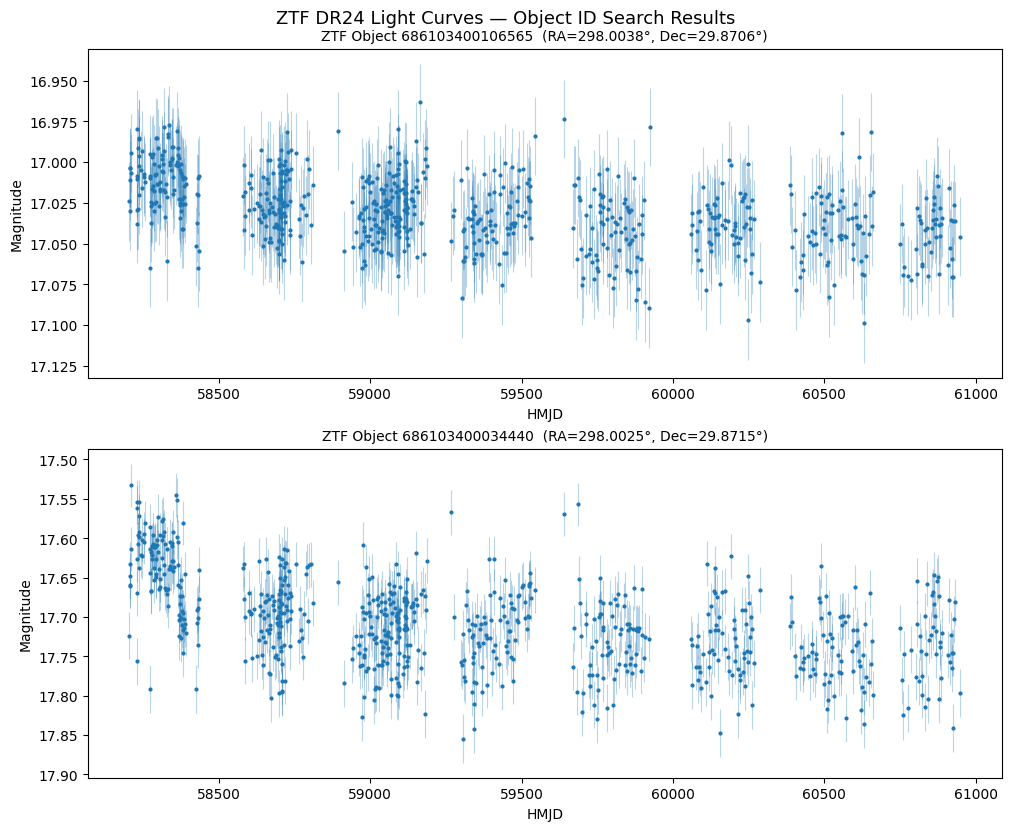

In [42]:
fig, axs = plt.subplots(len(ztf_lcs_by_id_df), 1,
                        figsize=(10, 4 * len(ztf_lcs_by_id_df)),
                        constrained_layout=True)

if len(ztf_lcs_by_id_df) == 1:
    axs = [axs]

for ax, (_, row) in zip(axs, ztf_lcs_by_id_df.iterrows()):
    lc = row['lightcurve'].query("catflags == 0")  # to keep only clean epochs
    title = f"ZTF Object {row['objectid']}  (RA={row['objra']:.4f}°, Dec={row['objdec']:.4f}°)"
    pts = ax.plot(lc['hmjd'], lc['mag'], '.', markersize=4, zorder=3)
    ax.errorbar(
        lc['hmjd'], lc['mag'], yerr=lc['magerr'],
        fmt='none', ecolor=pts[0].get_color(), elinewidth=0.8, alpha=0.3, zorder=2
    )
    ax.set_ylabel("Magnitude")
    ax.set_xlabel("HMJD")
    ax.invert_yaxis()
    ax.set_title(title, fontsize=10)

fig.suptitle("ZTF DR24 Light Curves — Object ID Search Results", fontsize=13, y=1.02)
plt.show()

### 4. Get Light Curves by Sky Position

如果您有天空坐标，并希望查找指定区域内所有ZTF天体，请使用[spatial search](https://docs.lsdb.io/en/latest/tutorials/region_selection.html)。此处我们将进行圆锥形搜索，此外也提供箱状和多边形搜索功能。

ZTF天体（即唯一的天体ID）是按（滤镜、字段、象限）来定义的。这意味着单个天体的观测通常会分散在多个不同的ZTF天体中。

对于一个给定的天体，最多可能由3个ZTF天体表示，每个滤镜各一个（g、r和i）。如果该天体位于某个ZTF区域或象限的边界附近，其各滤镜下的观测数据可能会进一步划分为多个额外的ZTF天体。

ZTF的像素分辨率为1"每像素，因此对于特定的天体，将搜索半径为1"的范围内所有ZTF天体进行合并可能是合理的。

####  4.1 Define a Spatial Filter and Row Filters

使用与[ ZTF light curve API docs](https://irsa.ipac.caltech.edu/docs/program_interface/ztf_lightcurve_api.html)中位置示例相同的天空位置，但可以指定任意坐标和搜索半径：

In [43]:
target = SkyCoord(ra=298.0025, dec=29.87147, unit="deg")
search_radius = 1 * u.arcsec # to keep the runtime minimal for this tutorial

spatial_filter = lsdb.ConeSearch(
    ra=target.ra.deg,
    dec=target.dec.deg,
    radius_arcsec=search_radius.to(u.arcsec).value
)

除了空间滤波器外，还可以使用Parquet列统计信息对行进行预过滤。此处仅保留具有超过25个观测周期的对象，重点关注采样良好的光变曲线：

In [44]:
row_filters = [
    ["nepochs", ">", 25],
    # additional filters can be added here if desired
    ]

#### 4.2 Open the Filtered Lightcurves Catalog

In [45]:
ztf_lc_cone = lsdb.open_catalog(
    f"s3://{ztf_bucket}/{ztf_lc_hats_prefix}",
    search_filter=spatial_filter,
    columns=ztf_lc_columns,
    filters=row_filters
)
ztf_lc_cone

,objectid,objra,objdec,filterid,nepochs,lightcurve
npartitions=1,,,,,,
"Order: 7, Pixel: 57663",int64[pyarrow],float[pyarrow],float[pyarrow],int8[pyarrow],int64[pyarrow],"nested<hmjd: [double], mag: [float], magerr: [float], clrcoeff: [float], catflags: [int32]>"


#### 4.3 Compute and Inspect the Results


In [47]:
with Client(n_workers=get_nworkers(ztf_lc_cone),
            threads_per_worker=1,
            memory_limit=None  # each partition can be several GB; avoid per-worker cap
            ) as client:
    print(f"You can monitor progress in the Dask dashboard at {client.dashboard_link}")
    ztf_lc_cone_df = ztf_lc_cone.compute()

You can monitor progress in the Dask dashboard at http://127.0.0.1:8787/status


2026-10-21 14:02:36,281 - distributed.worker.state_machine - WARNING - Async instruction for <Task cancelled name="execute(('read_pixel-a073ac7a2d159863fecef62b318aadae', 0))" coro=<Worker.execute() done, defined at /home/jovyan/work/envs/ztf/lib/python3.10/site-packages/distributed/worker_state_machine.py:3606>> ended with CancelledError
Process Dask Worker process (from Nanny):
Traceback (most recent call last):
  File "/home/jovyan/work/envs/ztf/lib/python3.10/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/home/jovyan/work/envs/ztf/lib/python3.10/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/home/jovyan/work/envs/ztf/lib/python3.10/site-packages/distributed/process.py", line 202, in _run
    target(*args, **kwargs)
  File "/home/jovyan/work/envs/ztf/lib/python3.10/site-packages/distributed/nanny.py", line 1037, in _run
    asyncio_run(run(), loop_factory=get_loop_factory())
  File "/home/jovyan/work

KeyboardInterrupt: 